# Comparing tTEM with tTEM

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from anemone.experiment import *
from anemone.inversion import *
from anemone.forwards import *

In [2]:
from libaarhusxyz import GEX
import plog

In [3]:
gex = GEX("TX11_3x3_1_turn.gex")

header [General] parsed
header [Channel1] parsed
header [Channel2] parsed


In [4]:
x,y = gex.General['TxLoopPoint'][:, 0], gex.General['TxLoopPoint'][:, 1]
x,y = np.append(x, x[0]),               np.append(y, y[0])
z   = np.ones_like(x)*abs(gex.General['TxCoilPosition'][2])
tx  = Loop(x,y,z)
rx  = Receiver(*abs(gex.General['RxCoilPosition']))

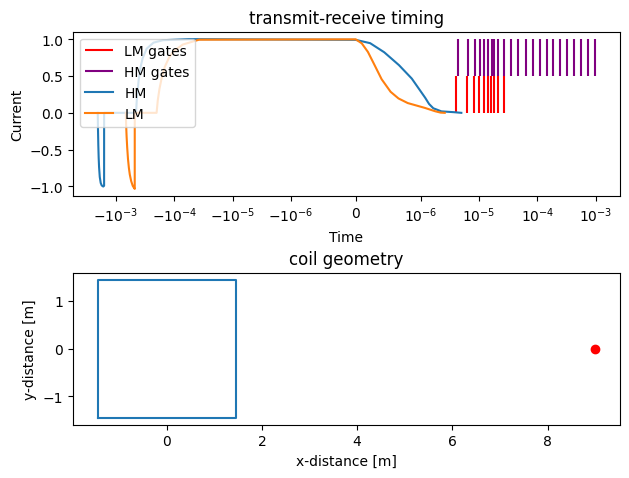

In [5]:
fig,axs=plt.subplots(2,1)
gex.plot(ax=axs[0])
axs[1].plot(tx.x, tx.y)
axs[1].plot(rx.x, rx.y, 'ro')
axs[1].set_aspect('equal')
axs[1].set_xlabel('x-distance [m]')
axs[1].set_ylabel('y-distance [m]')
axs[1].set_title('coil geometry')
axs[0].set_title('transmit-receive timing')
plt.tight_layout()

In [18]:
hmgates = torch.from_numpy(gex.gate_times('Channel2')[1:,0])
HMwv = Waveform(gex.General['WaveformHMPoint'][:, 0], gex.General['WaveformHMPoint'][:, 1])

recfilters = FilterChain([
    ButterworthFilter(6.79e5),
])

fwr3 = ForwardGeomOp(tx, rx, hmgates, waveform=HMwv, filterfunc=recfilters)

c:\users\au646858\onedrive - aarhus universitet\documents\_repositories\anemone\src\anemone\experiment\experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [61]:
n_mod = 15
rho = torch.ones((2,n_mod))*200
rho[0, :] = 0.3
# rho[1] = torch.linspace(5, 2e3, n_mod)
thick = torch.linspace(1, 10, n_mod).reshape((1,-1))


In [62]:
data3 = fwr3(rho, thick)

In [63]:
def set_line_colorcycle(ax, cmap='rainbow', n_lines=50):
    cm = plt.get_cmap(cmap)
    ax.set_prop_cycle(color=[cm(x) for x in np.linspace(0., 1., n_lines)])
    return cm

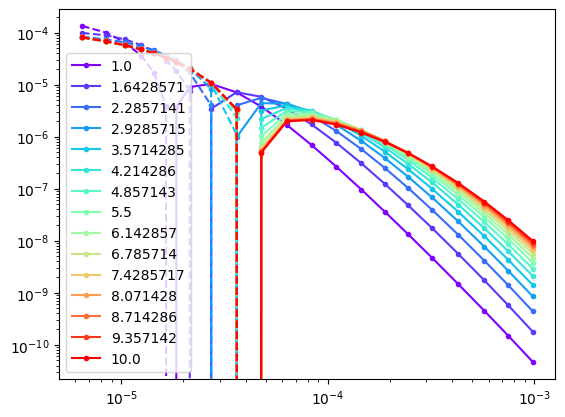

In [64]:
fig,axs = plt.subplots(1,1)
set_line_colorcycle(axs, n_lines=n_mod)
axs.loglog(fwr3.times, data3.T, '.-');
axs.loglog(fwr3.times, -data3.T, '.--');
axs.legend(labels=thick.squeeze().numpy())

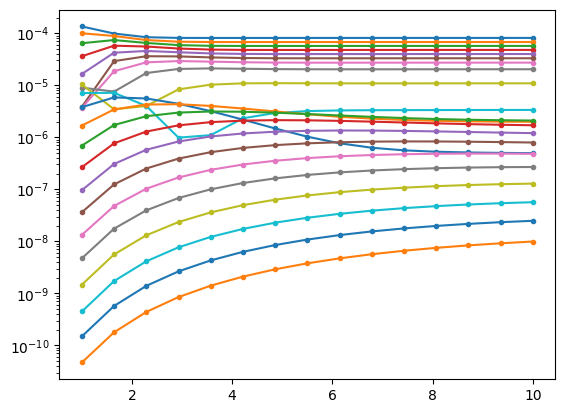

In [ ]:
fig,axs = plt.subplots(1,1)
axs.semilogy(thick.squeeze(), torch.abs(data3), '.');

In [ ]:
rho = torch.ones(2)*100

thick = torch.tensor([10])
data3 = fwr3(rho, thick)

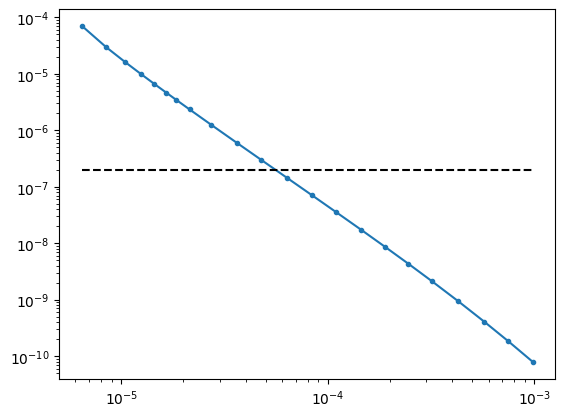

In [70]:
plt.figure()
plt.loglog(fwr3.times, data3*30, '.-');
plt.loglog(fwr3.times, torch.ones_like(fwr3.times)*200*1e-9, 'k--');

In [32]:
%%timeit
data0 = fwr0(rho, thick)

1.21 s ± 68.5 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [33]:
%%timeit
data3 = fwr3(rho, thick)

165 ms ± 3.79 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
